# Precious Metals Status

In [1]:
%%javascript
IPython.OutputArea.auto_scroll_threshold = 9999;

<IPython.core.display.Javascript object>

In [2]:
# ------------------------------------------------------------------------------
# PROJECT NAME: 'Helios'
# AUTHOR:       Tonmoy Roy
# LICENSE:      GNU LGPLv3
# ------------------------------------------------------------------------------
# REFERENCES:
# [1] https://panel.holoviz.org/
# ------------------------------------------------------------------------------

In [3]:
# IMPORT LIBRARIES
from datetime import datetime
from plotly.subplots import make_subplots

import math
import os
import pandas as pd
import plotly.graph_objects as go
import requests
import stat
import time

# ADJUST CONFIGURATOINS
pd.set_option("display.max_columns", None)

In [4]:
metaName = ['gold', 'silver', 'platinum', 'palladium']

met1Data = pd.DataFrame([])
met2Data = pd.DataFrame([])
met3Data = pd.DataFrame([])
met4Data = pd.DataFrame([])

for item in metaName:
    # REUSE OR DOWNLOAD DATA
    if os.path.exists('raw/' + str(item) + '_price.xlsx') and (time.time() - os.stat('raw/' + str(item) + '_price.xlsx')[stat.ST_MTIME]) <= (1*24*60*60):
        pass
    else:
        # SPECIFY URL ADDRESS FOR DATA SOURCE
        urlAddre = "https://prices.lbma.org.uk/export/xls/?c=%7B%22metals%22%3A%5B%22" + item + "%22%5D%2C%22type%22%3A%22daily%22%2C%22currency%22%3A%5B%22usd%22%5D%2C%22published%22%3A%5B%22am%22%5D%2C%22dates%22%3A%7B%22start%22%3A%221967-12-31%22%2C%22end%22%3A%22" + str(datetime.today().strftime('%Y-%m-%d')) + "%22%7D%7D"
        # DOWNLOAD DATA AND WRITE DATA TO FILE
        with open('raw/' + str(item) + '_price.xlsx', 'wb') as writFile:
            requData = requests.get(urlAddre, allow_redirects = True)
            writFile.write(requData.content)
    # READ DATA
    readData = pd.read_excel('raw/' + str(item) + '_price.xlsx', skiprows = [0], index_col = 'DATE', parse_dates = True).sort_index()
    # CLEAN UP INDEX AND COLUMN NAMES
    readData.index.names = ['date']
    if str(item) == 'silver':
        readData.rename(columns = {'-': 'price'}, inplace = True)  
    else:
        readData.rename(columns = {'AM': 'price'}, inplace = True)
    # COLLECT INTO CONTAINERS
    if str(item) == 'gold':
        met1Data = readData.copy()
        met1Data['1year_price_sma'] = math.nan
        met1Data['1year_price_ewma'] = math.nan
        met1Data['1year_price_sma'] = met1Data['price'].rolling(window = 252).mean()
        met1Data['1year_price_ewma'] = met1Data['price'].ewm(span = 252, adjust = False).mean()
        met1Data['0.5year_price_sma'] = met1Data['price'].rolling(window = 126).mean()
        met1Data['0.5year_price_ewma'] = met1Data['price'].ewm(span = 126, adjust = False).mean()
    elif str(item) == 'silver':
        met2Data = readData.copy()
        met2Data['1year_price_sma'] = math.nan
        met2Data['1year_price_ewma'] = math.nan
        met2Data['1year_price_sma'] = met2Data['price'].rolling(window = 252).mean()
        met2Data['1year_price_ewma'] = met2Data['price'].ewm(span = 252, adjust = False).mean()
        met2Data['0.5year_price_sma'] = met2Data['price'].rolling(window = 126).mean()
        met2Data['0.5year_price_ewma'] = met2Data['price'].ewm(span = 126, adjust = False).mean()
    elif str(item) == 'platinum':
        met3Data = readData.copy()
        met3Data['1year_price_sma'] = math.nan
        met3Data['1year_price_ewma'] = math.nan
        met3Data['1year_price_sma'] = met3Data['price'].rolling(window = 252).mean()
        met3Data['1year_price_ewma'] = met3Data['price'].ewm(span = 252, adjust = False).mean()
        met3Data['0.5year_price_sma'] = met3Data['price'].rolling(window = 126).mean()
        met3Data['0.5year_price_ewma'] = met3Data['price'].ewm(span = 126, adjust = False).mean()
    elif str(item) == 'palladium':
        met4Data = readData.copy()
        met4Data['1year_price_sma'] = math.nan
        met4Data['1year_price_ewma'] = math.nan
        met4Data['1year_price_sma'] = met4Data['price'].rolling(window = 252).mean()
        met4Data['1year_price_ewma'] = met4Data['price'].ewm(span = 252, adjust = False).mean()
        met4Data['0.5year_price_sma'] = met4Data['price'].rolling(window = 126).mean()
        met4Data['0.5year_price_ewma'] = met4Data['price'].ewm(span = 126, adjust = False).mean()

In [5]:
# SELECT DATE RANGE
dataRang = 1000

# Price History - Gold

In [6]:
# PLOT DATA
fig = make_subplots(specs = [[{"secondary_y": True}]])

fig.add_trace(
    go.Scatter(
        x = met1Data.index[-dataRang:], 
        y = met1Data['price'][-dataRang:], 
        name = 'Price Data - Gold'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met1Data.index[-dataRang:], 
        y = met1Data['1year_price_sma'][-dataRang:], 
        name = '1 Year SMA of Price Data - Gold'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met1Data.index[-dataRang:], 
        y = met1Data['1year_price_ewma'][-dataRang:], 
        name = '1 Year EWMA of Price Data - Gold'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met1Data.index[-dataRang:], 
        y = met1Data['0.5year_price_sma'][-dataRang:], 
        name = '0.5 Year SMA of Price Data - Gold'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met1Data.index[-dataRang:], 
        y = met1Data['0.5year_price_ewma'][-dataRang:], 
        name = '0.5 Year EWMA of Price Data - Gold'
    ), 
    secondary_y = False
)

fig.update_layout(
    width = 1600,
    height = 800,
    paper_bgcolor = 'White',
    plot_bgcolor = '#fafafa',
    hovermode = 'closest',
    title_text = 'Price Data for Gold with SMA/EWMA of Price Data',
    title_x = 0.46,
    xaxis = dict(title = 'Time'),
    yaxis = dict(title = 'Price, USD'),
    showlegend = True,
    legend = dict(orientation = 'h', yanchor = 'bottom', y = 0.9, xanchor = 'left', x = 0.0)
)

fig.update_xaxes(
    showline = True, 
    linewidth = 2, 
    linecolor = 'Black', 
    showgrid = True, 
    gridwidth = 1, 
    gridcolor = 'LightGrey'
)
fig.update_yaxes(
    showline = True, 
    linewidth = 2, 
    linecolor = 'Black', 
    showgrid = True, 
    gridwidth = 1, 
    gridcolor = 'LightGrey'
)

fig.show()

# Price History - Silver

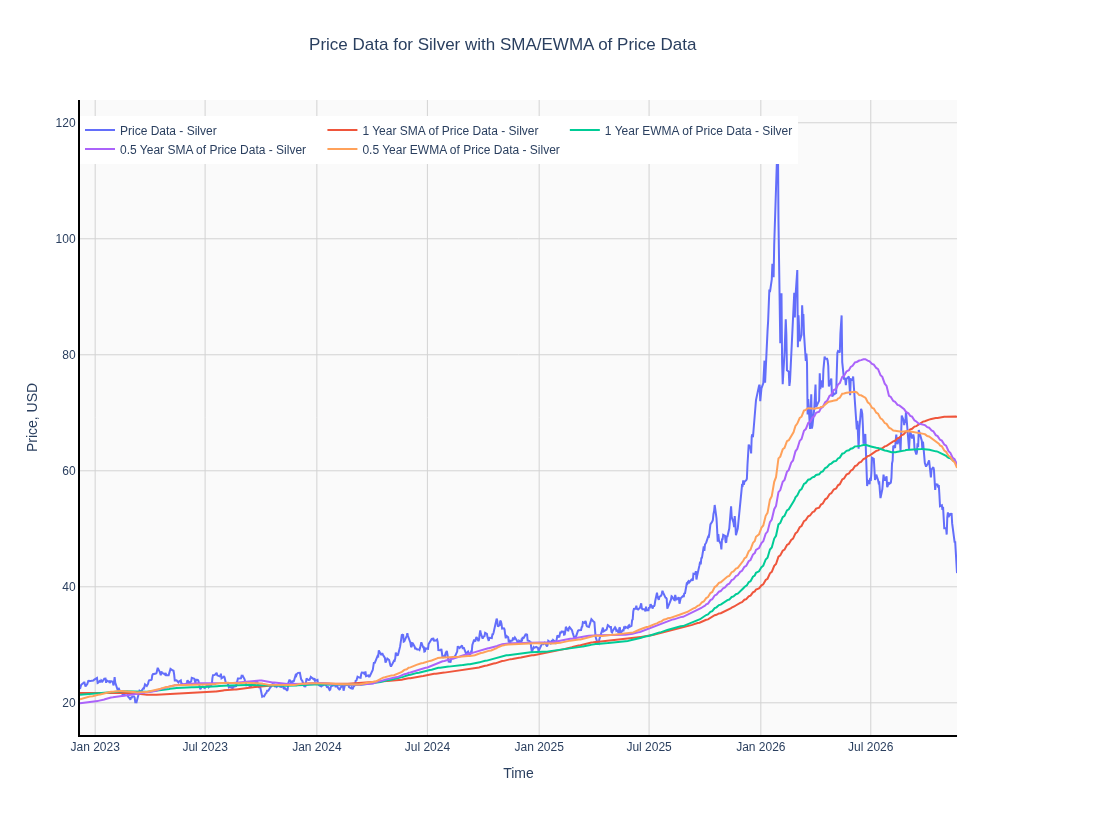

In [11]:
# PLOT DATA
fig = make_subplots(specs = [[{"secondary_y": True}]])

fig.add_trace(
    go.Scatter(
        x = met2Data.index[-dataRang:], 
        y = met2Data['price'][-dataRang:], 
        name = 'Price Data - Silver'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met2Data.index[-dataRang:], 
        y = met2Data['1year_price_sma'][-dataRang:], 
        name = '1 Year SMA of Price Data - Silver'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met2Data.index[-dataRang:], 
        y = met2Data['1year_price_ewma'][-dataRang:], 
        name = '1 Year EWMA of Price Data - Silver'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met2Data.index[-dataRang:], 
        y = met2Data['0.5year_price_sma'][-dataRang:], 
        name = '0.5 Year SMA of Price Data - Silver'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met2Data.index[-dataRang:], 
        y = met2Data['0.5year_price_ewma'][-dataRang:], 
        name = '0.5 Year EWMA of Price Data - Silver'
    ), 
    secondary_y = False
)

fig.update_layout(
    width = 1600,
    height = 800,
    paper_bgcolor = 'White',
    plot_bgcolor = '#fafafa',
    hovermode = 'closest',
    title_text = 'Price Data for Silver with SMA/EWMA of Price Data',
    title_x = 0.46,
    xaxis = dict(title = 'Time'),
    yaxis = dict(title = 'Price, USD'),
    showlegend = True,
    legend = dict(orientation = 'h', yanchor = 'bottom', y = 0.9, xanchor = 'left', x = 0.0)
)

fig.update_xaxes(
    showline = True, 
     linewidth = 2, 
     linecolor = 'Black',
     showgrid = True,
     gridwidth = 1,
     gridcolor = 'LightGrey'
)
fig.update_yaxes(
    showline = True, 
     linewidth = 2, 
     linecolor = 'Black',
     showgrid = True,
     gridwidth = 1,
     gridcolor = 'LightGrey'
)

fig.show()

# Price History - Platinum

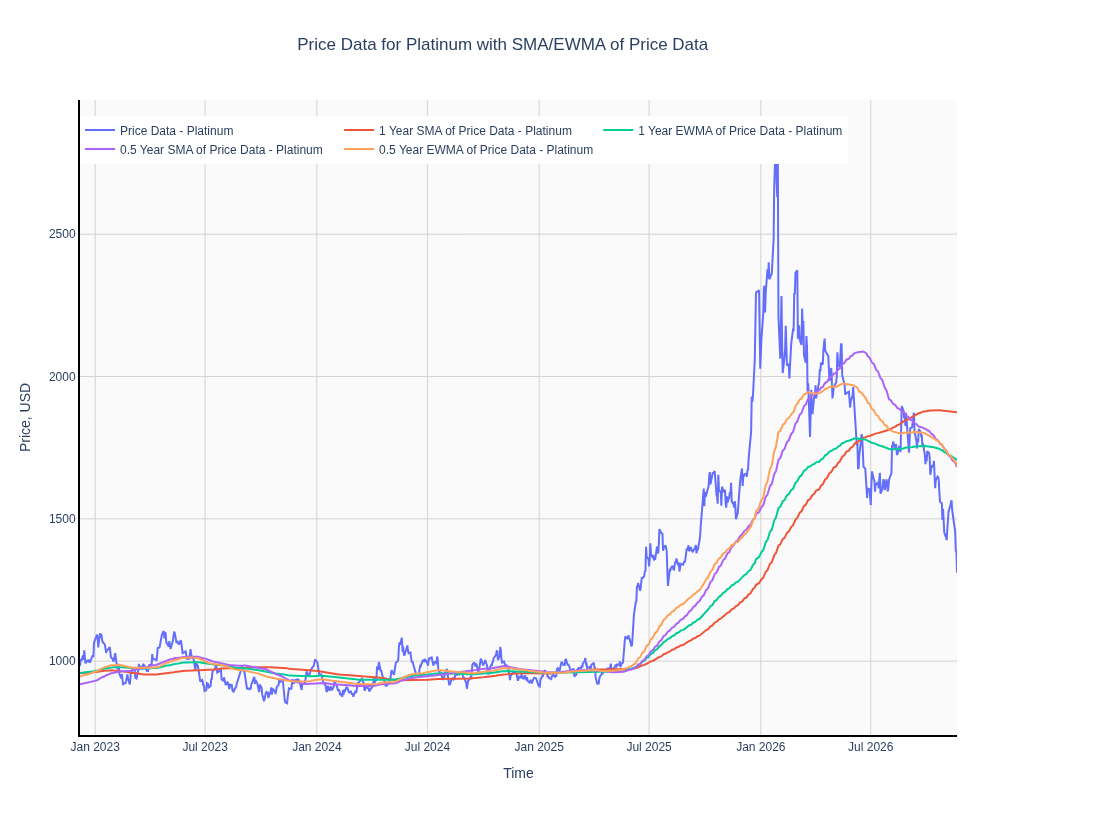

In [12]:
# PLOT DATA
fig = make_subplots(specs = [[{"secondary_y": True}]])

fig.add_trace(
    go.Scatter(
        x = met3Data.index[-dataRang:], 
        y = met3Data['price'][-dataRang:], 
        name = 'Price Data - Platinum'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met3Data.index[-dataRang:], 
        y = met3Data['1year_price_sma'][-dataRang:], 
        name = '1 Year SMA of Price Data - Platinum'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met3Data.index[-dataRang:], 
        y = met3Data['1year_price_ewma'][-dataRang:], 
        name = '1 Year EWMA of Price Data - Platinum'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met3Data.index[-dataRang:], 
        y = met3Data['0.5year_price_sma'][-dataRang:], 
        name = '0.5 Year SMA of Price Data - Platinum'
    ), 
    secondary_y = False
)

fig.add_trace(
    go.Scatter(
        x = met3Data.index[-dataRang:], 
        y = met3Data['0.5year_price_ewma'][-dataRang:], 
        name = '0.5 Year EWMA of Price Data - Platinum'
    ), 
    secondary_y = False
)

fig.update_layout(
    width = 1600,
    height = 800,
    paper_bgcolor = 'White',
    plot_bgcolor = '#fafafa',
    hovermode = 'closest',
    title_text = 'Price Data for Platinum with SMA/EWMA of Price Data',
    title_x = 0.46,
    xaxis = dict(title = 'Time'),
    yaxis = dict(title = 'Price, USD'),
    showlegend = True,
    legend = dict(orientation = 'h', yanchor = 'bottom', y = 0.9, xanchor = 'left', x = 0.0)
)

fig.update_xaxes(
    showline = True, 
     linewidth = 2, 
     linecolor = 'Black',
     showgrid = True,
     gridwidth = 1,
     gridcolor = 'LightGrey'
)
fig.update_yaxes(
    showline = True, 
    linewidth = 2, 
    linecolor = 'Black',
    showgrid = True,
    gridwidth = 1,
    gridcolor = 'LightGrey'
)

fig.show()

# Price History - Palladium

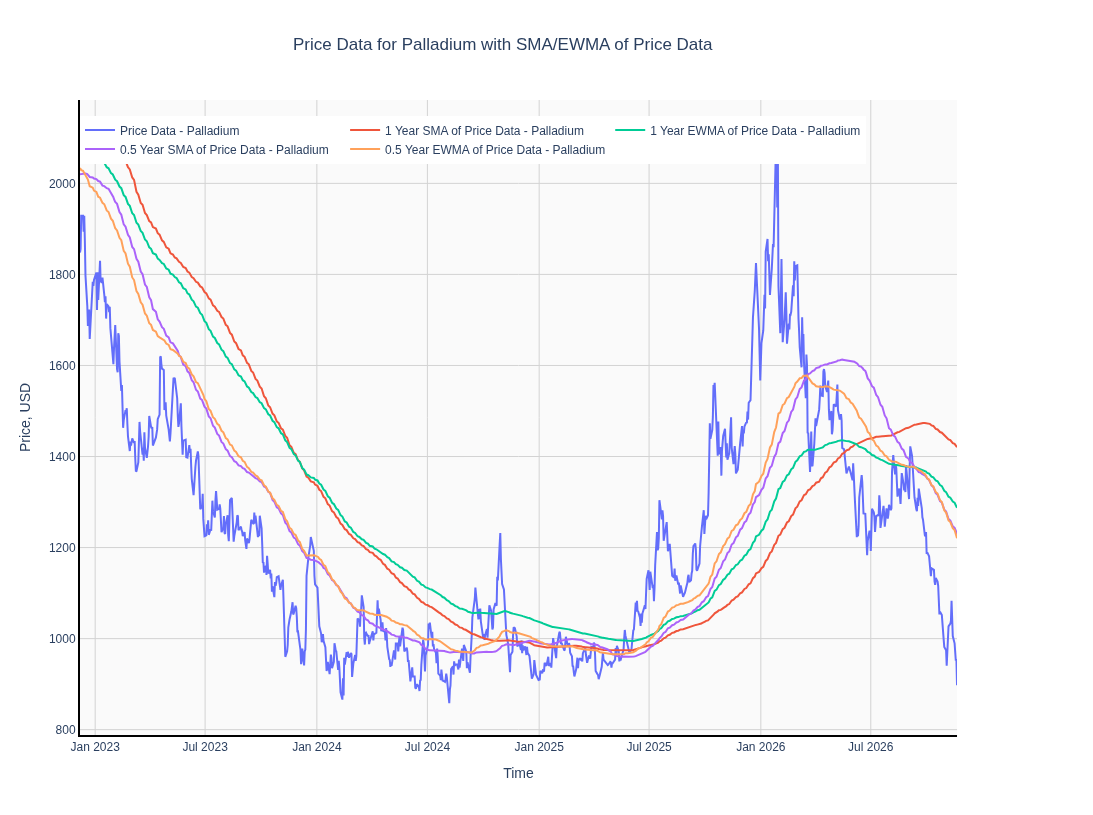

In [13]:
# PLOT DATA
fig = make_subplots(specs = [[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x = met4Data.index[-dataRang:], 
                         y = met4Data['price'][-dataRang:], 
                         name = 'Price Data - Palladium'), 
              secondary_y = False
             )

fig.add_trace(go.Scatter(x = met4Data.index[-dataRang:], 
                         y = met4Data['1year_price_sma'][-dataRang:], 
                         name = '1 Year SMA of Price Data - Palladium'), 
              secondary_y = False
             )

fig.add_trace(go.Scatter(x = met4Data.index[-dataRang:], 
                         y = met4Data['1year_price_ewma'][-dataRang:], 
                         name = '1 Year EWMA of Price Data - Palladium'), 
              secondary_y = False
             )

fig.add_trace(go.Scatter(x = met4Data.index[-dataRang:], 
                         y = met4Data['0.5year_price_sma'][-dataRang:], 
                         name = '0.5 Year SMA of Price Data - Palladium'), 
              secondary_y = False
             )

fig.add_trace(go.Scatter(x = met4Data.index[-dataRang:], 
                         y = met4Data['0.5year_price_ewma'][-dataRang:], 
                         name = '0.5 Year EWMA of Price Data - Palladium'), 
              secondary_y = False
             )

fig.update_layout(
    width = 1600,
    height = 800,
    paper_bgcolor = 'White',
    plot_bgcolor = '#fafafa',
    hovermode = 'closest',
    title_text = 'Price Data for Palladium with SMA/EWMA of Price Data',
    title_x = 0.46,
    xaxis = dict(title = 'Time'),
    yaxis = dict(title = 'Price, USD'),
    showlegend = True,
    legend = dict(orientation = 'h', yanchor = 'bottom', y = 0.9, xanchor = 'left', x = 0.0)
)

fig.update_xaxes(showline = True, 
                 linewidth = 2, 
                 linecolor = 'Black',
                 showgrid = True,
                 gridwidth = 1,
                 gridcolor = 'LightGrey'
                )
fig.update_yaxes(showline = True, 
                 linewidth = 2, 
                 linecolor = 'Black',
                 showgrid = True,
                 gridwidth = 1,
                 gridcolor = 'LightGrey'
                )

fig.show()

## References 

In [10]:
# [1] https://www.lbma.org.uk/prices-and-data/precious-metal-prices#/